<a href="https://colab.research.google.com/github/priya25-art/Machine-Learning/blob/main/Decision_Tree_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:
import pandas as pd
excel_path = '/content/ML_data.xlsx'
excel_file = pd.ExcelFile(excel_path)
print('Sheet names:', excel_file.sheet_names)
df = pd.read_excel(excel_path, sheet_name=0)
print('Columns:', df.columns.tolist())
print('Shape:', df.shape)
print(df.head())

Sheet names: ['Sheet1']
Columns: ['Student_ID', 'Department', 'Attendance', 'Internal_Marks', 'Study_Hours', 'Backlogs', 'Gender', 'Final_Result']
Shape: (5, 8)
   Student_ID Department  Attendance  Internal_Marks  Study_Hours  Backlogs  \
0         101        CSE          85            78.0           12         0   
1         102         IT          62            45.0            5         2   
2         103        CSE          91            88.0           15         0   
3         104        ECE          74             NaN            8         1   
4         105         IT          55            39.0            4         3   

   Gender Final_Result  
0  Female         Pass  
1    Male         Fail  
2  Female         Pass  
3    Male         Pass  
4  Female         Fail  


Train accuracy: 1.0
Test accuracy: 1.0


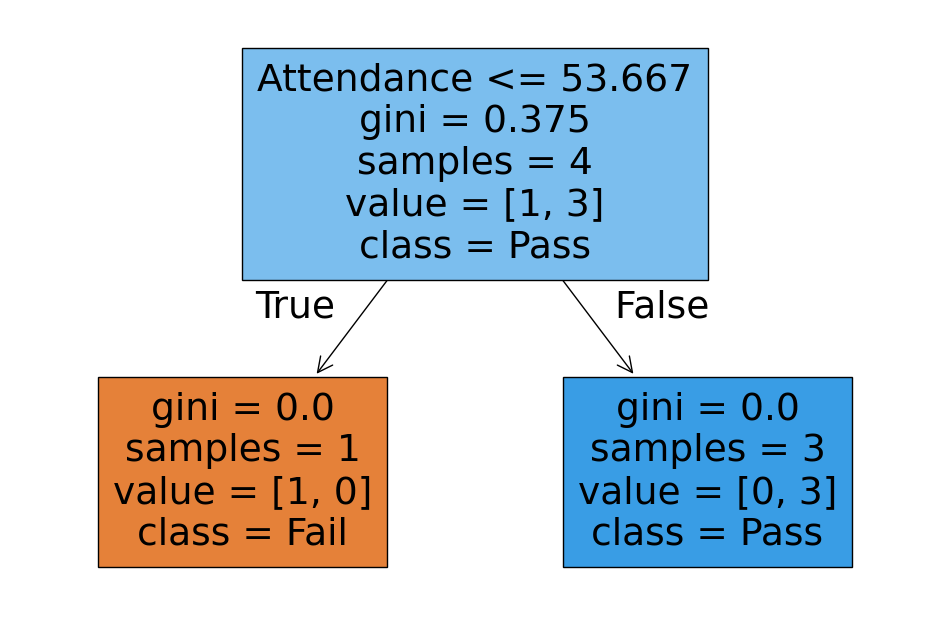

In [42]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

# Load data
df = pd.read_excel('ML_data.xlsx')

# Features and target
X = df.drop(columns=['Student_ID', 'Final_Result'])
y = df['Final_Result']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Example: Decision Tree pipeline
numeric_features = X.select_dtypes(include=['int64','float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

numeric_transformer = SimpleImputer(strategy='mean')
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Train model
clf.fit(X_train, y_train)

# Evaluate
print("Train accuracy:", clf.score(X_train, y_train))
print("Test accuracy:", clf.score(X_test, y_test))

# Visualize tree
plt.figure(figsize=(12,8))
plot_tree(clf.named_steps['classifier'], filled=True, feature_names=X.columns, class_names=clf.classes_)
plt.show()


In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline

# Define the classifiers
models = {
    "logistic regression": LogisticRegression(max_iter=1000),
    "decision tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "random forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

# Loop through each model, create a pipeline with our preprocessor, train, and evaluate
for name, classifier in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', classifier)
    ])

    # Fit on training data
    pipeline.fit(X_train, y_train)

    # Predict on test data
    predictions = pipeline.predict(X_test)

    print(f"\n{name.upper()}:")
    print(classification_report(y_test, predictions, zero_division=0))


LOGISTIC REGRESSION:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1

    accuracy                           1.00         1
   macro avg       1.00      1.00      1.00         1
weighted avg       1.00      1.00      1.00         1


DECISION TREE:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1

    accuracy                           1.00         1
   macro avg       1.00      1.00      1.00         1
weighted avg       1.00      1.00      1.00         1


RANDOM FOREST:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1

    accuracy                           1.00         1
   macro avg       1.00      1.00      1.00         1
weighted avg       1.00      1.00      1.00         1



In [44]:
pip install pandas scikit-learn openpyxl matplotlib

Available sheet names: ['Sheet1']
Raw Dataset shape: (28, 9)
Dataset shape after removing duplicates: (25, 9)

[1] Decision Tree Regressor trained successfully!


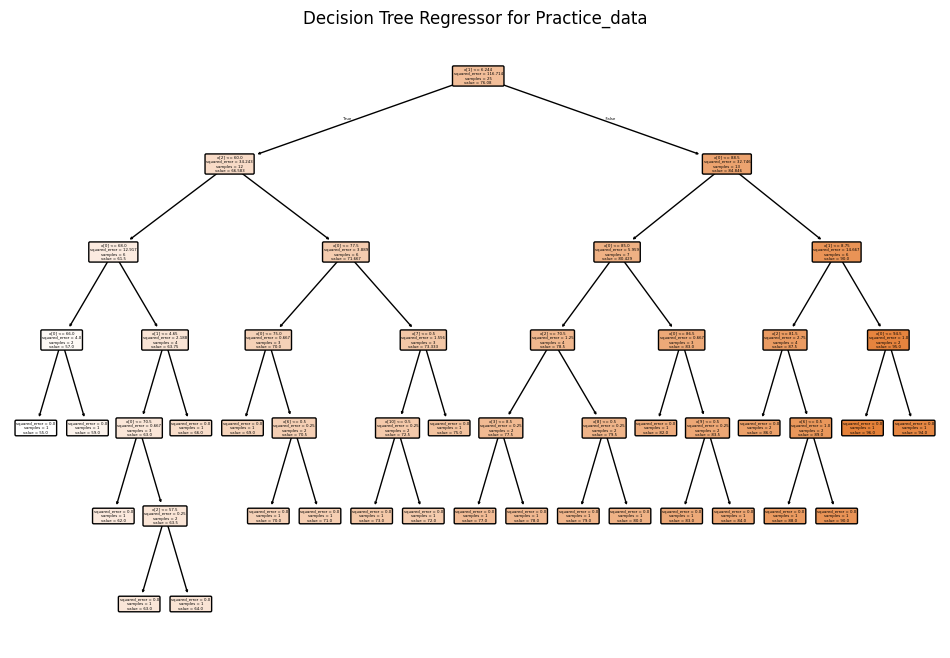


[2] Computed CCP Alphas for Pruning: [0.00000000e+00 2.00000000e-02 2.00000000e-02 2.00000000e-02
 2.00000000e-02 2.00000000e-02 2.00000000e-02 6.00000000e-02
 6.00000000e-02 6.00000000e-02 8.00000000e-02 8.00000000e-02
 1.60000000e-01 1.66666667e-01 2.70000000e-01 3.20000000e-01
 3.60000000e-01 6.66666667e-01 1.38857143e+00 2.43000000e+00
 3.00000000e+00 1.18391209e+01 1.24033333e+01 8.32492410e+01]
Pruned Decision Tree Regressor trained successfully with ccp_alpha=12.403333333333684!

[3] Random Forest Regressor trained successfully!
Sample Predictions from Random Forest: [77.93 86.04 69.99 83.82 63.76]


In [46]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

excel_path = '/content/Practice_data_with_pass_fail.xlsx'
xls = pd.ExcelFile(excel_path)
print("Available sheet names:", xls.sheet_names)

# 1. Load the correct dataset into df
df = pd.read_excel(excel_path)
print("Raw Dataset shape:", df.shape)

# 2. Data Cleaning (Handling Duplicates & Missing Values)
df = df.drop_duplicates()
print("Dataset shape after removing duplicates:", df.shape)

# Separate features (X) and target (y)
# Drop Student_ID (identifier) and Final_Score (target)
X = df.drop(columns=['Student_ID', 'Final_Score'])
y = df['Final_Score']

# Identify numeric and categorical columns
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X.select_dtypes(include=['object']).columns

# 3. Build Preprocessing Pipeline
numeric_transformer = SimpleImputer(strategy='mean')
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# ==========================================
# 4. Decision Tree Regressor
# ==========================================
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor(random_state=42))
])

dt_pipeline.fit(X, y)
print("\n[1] Decision Tree Regressor trained successfully!")

# Visualize the trained Decision Tree
plt.figure(figsize=(12, 8))
plot_tree(dt_pipeline.named_steps['regressor'], filled=True, rounded=True)
plt.title("Decision Tree Regressor for Practice_data")
plt.show()

# ==========================================
# 5. Cost-Complexity Pruning (Pruned Tree)
# ==========================================
X_transformed = preprocessor.fit_transform(X)
base_dt = DecisionTreeRegressor(random_state=42)
path = base_dt.cost_complexity_pruning_path(X_transformed, y)
ccp_alphas = path.ccp_alphas

print(f"\n[2] Computed CCP Alphas for Pruning: {ccp_alphas}")

best_alpha = ccp_alphas[-2] if len(ccp_alphas) > 1 else 0.0

pruned_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor(random_state=42, ccp_alpha=best_alpha))
])

pruned_pipeline.fit(X, y)
print(f"Pruned Decision Tree Regressor trained successfully with ccp_alpha={best_alpha}!")

# ==========================================
# 6. Random Forest Regressor
# ==========================================
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

rf_pipeline.fit(X, y)
print("\n[3] Random Forest Regressor trained successfully!")

# Make predictions on the dataset
predictions = rf_pipeline.predict(X)
print("Sample Predictions from Random Forest:", predictions[:5])

In [35]:
"""
Pass/Fail prediction with Decision Tree, Cost-Complexity Pruning and Random Forest.
"""
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

RANDOM_STATE = 42

# Direct assignment of the spreadsheet file path
path = "Practice_data_with_pass_fail.xlsx"

# ---------------------------------------------------------------------------
# 1. Load and clean
# ---------------------------------------------------------------------------
df = pd.read_excel(path)
print(f"Raw rows: {len(df)}")

# Exact duplicate rows (e.g. Student_ID 1006, 1012, 1020 appear twice)
df = df.drop_duplicates()
print(f"Rows after removing duplicates: {len(df)}")

# Final_Score is excluded from the features: pass/fail is decided from it,
# so keeping it would leak the answer into the model.
TARGET = "pass_fail"
DROP_COLS = ["Student_ID", "Final_Score", TARGET]

X = df.drop(columns=DROP_COLS)
y = (df[TARGET].str.strip().str.lower() == "pass").astype(int)  # Pass=1, Fail=0

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print(f"Numeric features: {num_cols}")
print(f"Categorical features: {cat_cols}")
print(f"Class balance: {y.value_counts().to_dict()}  (1 = Pass)\n")

# Imputation and encoding live inside the pipeline, so they are learned
# from training data only and never see the test set.
preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    print(f"===== {name} =====")
    print(f"Test accuracy: {accuracy_score(y_te, pred):.3f}")
    print("Confusion matrix (rows = actual Fail/Pass, cols = predicted Fail/Pass):")
    print(confusion_matrix(y_te, pred, labels=[0, 1]))
    print(classification_report(y_te, pred, target_names=["Fail", "Pass"], zero_division=0))
    return model

# ---------------------------------------------------------------------------
# 2. Decision Tree (no pruning - grows until leaves are pure)
# ---------------------------------------------------------------------------
dt_full = Pipeline([
    ("prep", preprocessor),
    ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])
dt_full = evaluate("Decision Tree (unpruned)", dt_full, X_train, y_train, X_test, y_test)
print(f"Unpruned tree depth: {dt_full.named_steps['clf'].get_depth()}, "
      f"leaves: {dt_full.named_steps['clf'].get_n_leaves()}")
print(f"5-fold CV accuracy (train): {cross_val_score(dt_full, X_train, y_train, cv=cv).mean():.3f}\n")

# ---------------------------------------------------------------------------
# 3. Pruning - Minimal Cost-Complexity Pruning (ccp_alpha)
# ---------------------------------------------------------------------------
# Get the candidate alphas from the pruning path of the training data.
X_train_enc = preprocessor.fit(X_train).transform(X_train)
path_info = DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(
    X_train_enc, y_train
)
ccp_alphas = np.unique(path_info.ccp_alphas)

pruned_search = GridSearchCV(
    Pipeline([
        ("prep", preprocessor),
        ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    param_grid={"clf__ccp_alpha": ccp_alphas},
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
)
pruned_search.fit(X_train, y_train)
best_alpha = pruned_search.best_params_["clf__ccp_alpha"]
print(f"Best ccp_alpha from CV: {best_alpha:.5f} "
      f"(CV accuracy {pruned_search.best_score_:.3f})")

dt_pruned = evaluate("Decision Tree (pruned)", pruned_search.best_estimator_,
                     X_train, y_train, X_test, y_test)
pruned_tree = dt_pruned.named_steps["clf"]
print(f"Pruned tree depth: {pruned_tree.get_depth()}, leaves: {pruned_tree.get_n_leaves()}")

feature_names = dt_pruned.named_steps["prep"].get_feature_names_out()
print("\nPruned tree rules:")
print(export_text(pruned_tree, feature_names=list(feature_names)))

# Save a picture of the pruned tree
fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(pruned_tree, feature_names=feature_names, class_names=["Fail", "Pass"],
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Pruned Decision Tree - Pass/Fail")
plt.tight_layout()
plt.savefig("pruned_decision_tree.png", dpi=150)
plt.close()
print("Saved tree diagram to pruned_decision_tree.png\n")

# ---------------------------------------------------------------------------
# 4. Random Forest
# ---------------------------------------------------------------------------
rf = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        oob_score=True,
        random_state=RANDOM_STATE,
    )),
])

# Light tuning of the forest
rf_search = GridSearchCV(
    rf,
    param_grid={
        "clf__max_depth": [None, 3, 5],
        "clf__min_samples_leaf": [1, 2, 3],
        "clf__max_features": ["sqrt", 0.5],
    },
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
)
rf_search.fit(X_train, y_train)
print(f"Best Random Forest params: {rf_search.best_params_} "
      f"(CV accuracy {rf_search.best_score_:.3f})")

rf_best = evaluate("Random Forest (tuned)", rf_search.best_estimator_,
                   X_train, y_train, X_test, y_test)
rf_clf = rf_best.named_steps["clf"]
print(f"Out-of-bag accuracy: {rf_clf.oob_score_:.3f}")

importances = pd.Series(rf_clf.feature_importances_, index=feature_names).sort_values(ascending=False)
print("\nRandom Forest feature importances:")
print(importances.round(3).to_string())

# ---------------------------------------------------------------------------
# 5. Side-by-side comparison
# ---------------------------------------------------------------------------
print("\n===== Summary (test accuracy / 5-fold CV accuracy on training data) =====")
for name, model in [
    ("Decision Tree (unpruned)", dt_full),
    ("Decision Tree (pruned)", dt_pruned),
    ("Random Forest (tuned)", rf_best),
]:
    test_acc = accuracy_score(y_test, model.predict(X_test))
    cv_acc = cross_val_score(model, X_train, y_train, cv=cv).mean()
    print(f"{name:28s} test={test_acc:.3f}   cv={cv_acc:.3f}")

Raw rows: 28
Rows after removing duplicates: 25
Numeric features: ['Attendance_Pct', 'Study_Hours_Per_Day', 'Internal_Marks', 'Assignments_Completed']
Categorical features: ['Department', 'Gender']
Class balance: {1: 17, 0: 8}  (1 = Pass)

===== Decision Tree (unpruned) =====
Test accuracy: 0.750
Confusion matrix (rows = actual Fail/Pass, cols = predicted Fail/Pass):
[[3 0]
 [2 3]]
              precision    recall  f1-score   support

        Fail       0.60      1.00      0.75         3
        Pass       1.00      0.60      0.75         5

    accuracy                           0.75         8
   macro avg       0.80      0.80      0.75         8
weighted avg       0.85      0.75      0.75         8

Unpruned tree depth: 1, leaves: 2
5-fold CV accuracy (train): 1.000

Best ccp_alpha from CV: 0.00000 (CV accuracy 1.000)
===== Decision Tree (pruned) =====
Test accuracy: 0.750
Confusion matrix (rows = actual Fail/Pass, cols = predicted Fail/Pass):
[[3 0]
 [2 3]]
              precision 

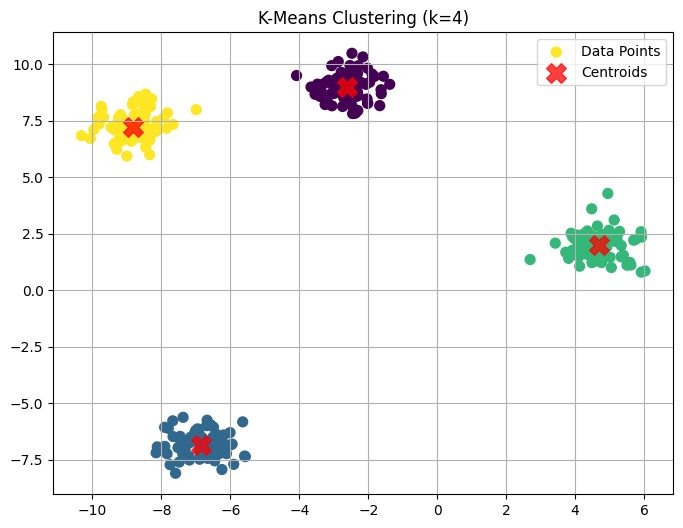

In [39]:
#  K-means clustering
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs  # Kind of data

# Initialize data and K-Means
x, y = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=42)
kmeans = KMeans(n_clusters=4, init='k-means++', max_iter=300, random_state=42)



# Fit and predict
y_kmeans = kmeans.fit_predict(x)

# Plot clusters
plt.figure(figsize=(8, 6))
plt.scatter(x[:, 0], x[:, 1], c=y_kmeans, s=50, cmap='viridis', label='Data Points')

# Plot centroids
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.75, marker='X', label='Centroids')
plt.title("K-Means Clustering (k=4)")
plt.legend()
plt.grid(True)
plt.show()

In [40]:
centroid_df = pd.DataFrame(centers, columns=['Feature1', 'Feature2'])
print("Centroids:")
print(centroid_df) # Centroids

Centroids:
   Feature1  Feature2
0 -2.605169  8.992801
1 -6.851262 -6.850318
2  4.686874  2.014346
3 -8.834561  7.244307
